In [ ]:
from google.colab import files

uploaded = files.upload()

Saving train_values.csv to train_values.csv
Saving train_labels.csv to train_labels.csv


Load the datasets

In [ ]:
import pandas as pd

train_values = pd.read_csv("train_values.csv")
train_labels = pd.read_csv("train_labels.csv")

print("Train values shape:", train_values.shape)
print("Train labels shape:", train_labels.shape)

Train values shape: (260601, 39)
Train labels shape: (260601, 2)


Merge

In [ ]:
df = train_values.merge(train_labels, on="building_id")

print("Merged dataset shape:", df.shape)

Merged dataset shape: (260601, 40)


See all columns

In [ ]:
print("Columns in our dataset:\n")
for i, col in enumerate(df.columns, 1):
    print(i, ":", col)

Columns in our dataset:

1 : building_id
2 : geo_level_1_id
3 : geo_level_2_id
4 : geo_level_3_id
5 : count_floors_pre_eq
6 : age
7 : area_percentage
8 : height_percentage
9 : land_surface_condition
10 : foundation_type
11 : roof_type
12 : ground_floor_type
13 : other_floor_type
14 : position
15 : plan_configuration
16 : has_superstructure_adobe_mud
17 : has_superstructure_mud_mortar_stone
18 : has_superstructure_stone_flag
19 : has_superstructure_cement_mortar_stone
20 : has_superstructure_mud_mortar_brick
21 : has_superstructure_cement_mortar_brick
22 : has_superstructure_timber
23 : has_superstructure_bamboo
24 : has_superstructure_rc_non_engineered
25 : has_superstructure_rc_engineered
26 : has_superstructure_other
27 : legal_ownership_status
28 : count_families
29 : has_secondary_use
30 : has_secondary_use_agriculture
31 : has_secondary_use_hotel
32 : has_secondary_use_rental
33 : has_secondary_use_institution
34 : has_secondary_use_school
35 : has_secondary_use_industry
36 : has_

separate X and y

In [ ]:
X = df.drop(columns=["damage_grade", "building_id"])
y = df["damage_grade"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (260601, 38)
y shape: (260601,)


Check data types

In [ ]:
print("Data types of all features:\n")
print(X.dtypes)

Data types of all features:

geo_level_1_id                             int64
geo_level_2_id                             int64
geo_level_3_id                             int64
count_floors_pre_eq                        int64
age                                        int64
area_percentage                            int64
height_percentage                          int64
land_surface_condition                    object
foundation_type                           object
roof_type                                 object
ground_floor_type                         object
other_floor_type                          object
position                                  object
plan_configuration                        object
has_superstructure_adobe_mud               int64
has_superstructure_mud_mortar_stone        int64
has_superstructure_stone_flag              int64
has_superstructure_cement_mortar_stone     int64
has_superstructure_mud_mortar_brick        int64
has_superstructure_cement_mortar_brick  

separate categorical and numerical features

In [ ]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumber of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numerical_features)

print("\nNumber of numerical features:", len(numerical_features))

Categorical features:
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

Number of categorical features: 8

Numerical features:
['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post

check missing valuesDamage-grade distribution

In [ ]:
missing_values = X.isnull().sum()

print("Total missing values:", missing_values.sum())

print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


In [ ]:
print("Damage Grade Distribution:")
print(y.value_counts().sort_index())

print("\nPercentage Distribution:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Damage Grade Distribution:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64

Percentage Distribution:
damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64


Split the data into training and validation sets

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)

print("\nTraining labels:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nValidation labels:")
print(y_val.value_counts(normalize=True).sort_index().round(4))

Training set: (208480, 38)
Validation set: (52121, 38)

Training labels:
damage_grade
1    0.0964
2    0.5689
3    0.3347
Name: proportion, dtype: float64

Validation labels:
damage_grade
1    0.0964
2    0.5689
3    0.3347
Name: proportion, dtype: float64


Preprocessing

In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


transform the data

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Processed training data shape:", X_train_processed.shape)
print("Processed validation data shape:", X_val_processed.shape)

Processed training data shape: (208480, 68)
Processed validation data shape: (52121, 68)


Select the 20 best features for KNN

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=20)

X_train_knn = selector.fit_transform(X_train_processed, y_train)
X_val_knn = selector.transform(X_val_processed)

print("KNN training shape:", X_train_knn.shape)
print("KNN validation shape:", X_val_knn.shape)

KNN training shape: (208480, 20)
KNN validation shape: (52121, 20)


Train KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=7,
    n_jobs=-1
)

knn.fit(X_train_knn, y_train)

print("KNN training completed.")

KNN training completed.


KNN prediction + evaluation

In [ ]:

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Use a smaller validation sample for KNN evaluation
X_val_knn_small = X_val_knn[:10000]
y_val_knn_small = y_val.iloc[:10000]

print("KNN evaluation samples:", len(y_val_knn_small))

y_pred_knn = knn.predict(X_val_knn_small)

knn_accuracy = accuracy_score(y_val_knn_small, y_pred_knn)
knn_f1 = f1_score(y_val_knn_small, y_pred_knn, average="micro")

print("KNN Accuracy:", round(knn_accuracy, 4))
print("KNN Micro-F1:", round(knn_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val_knn_small, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_knn_small, y_pred_knn))

KNN evaluation samples: 10000
KNN Accuracy: 0.6446
KNN Micro-F1: 0.6446

Classification Report:
              precision    recall  f1-score   support

           1       0.49      0.40      0.44      1014
           2       0.67      0.76      0.71      5682
           3       0.64      0.52      0.57      3304

    accuracy                           0.64     10000
   macro avg       0.60      0.56      0.57     10000
weighted avg       0.64      0.64      0.64     10000


Confusion Matrix:
[[ 401  590   23]
 [ 388 4341  953]
 [  31 1569 1704]]


Neural Network

In [ ]:
from sklearn.neural_network import MLPClassifier

nn_model = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation="logistic",
    solver="adam",
    alpha=0.0001,
    batch_size=1000,
    learning_rate_init=0.002,
    max_iter=30,
    random_state=42,
    verbose=True
)

nn_model.fit(X_train_processed, y_train)

print("Neural Network training completed.")

Iteration 1, loss = 0.90780377
Iteration 2, loss = 0.80153856
Iteration 3, loss = 0.79005242
Iteration 4, loss = 0.78377102
Iteration 5, loss = 0.77875369
Iteration 6, loss = 0.77456241
Iteration 7, loss = 0.77131409
Iteration 8, loss = 0.76846885
Iteration 9, loss = 0.76619927
Iteration 10, loss = 0.76446920
Iteration 11, loss = 0.76305475
Iteration 12, loss = 0.76201838
Iteration 13, loss = 0.76105248
Iteration 14, loss = 0.76047787
Iteration 15, loss = 0.75985047
Iteration 16, loss = 0.75916550
Iteration 17, loss = 0.75863813
Iteration 18, loss = 0.75803621
Iteration 19, loss = 0.75769733
Iteration 20, loss = 0.75718022
Iteration 21, loss = 0.75669689
Iteration 22, loss = 0.75630126
Iteration 23, loss = 0.75591725
Iteration 24, loss = 0.75532579
Iteration 25, loss = 0.75490955
Iteration 26, loss = 0.75451113
Iteration 27, loss = 0.75402804
Iteration 28, loss = 0.75356805
Iteration 29, loss = 0.75313095
Iteration 30, loss = 0.75270826
Neural Network training completed.


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Neural Network prediction

In [ ]:
y_pred_nn = nn_model.predict(X_val_processed)

nn_accuracy = accuracy_score(y_val, y_pred_nn)
nn_f1 = f1_score(y_val, y_pred_nn, average="micro")

print("Neural Network Accuracy:", round(nn_accuracy, 4))
print("Neural Network Micro-F1:", round(nn_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_nn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_nn))

Neural Network Accuracy: 0.6304
Neural Network Micro-F1: 0.6304

Classification Report:
              precision    recall  f1-score   support

           1       0.60      0.35      0.45      5025
           2       0.64      0.81      0.72     29652
           3       0.60      0.40      0.48     17444

    accuracy                           0.63     52121
   macro avg       0.61      0.52      0.55     52121
weighted avg       0.62      0.63      0.61     52121


Confusion Matrix:
[[ 1781  2994   250]
 [ 1098 24099  4455]
 [   75 10390  6979]]


RANDOM FOREST

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed.")

Random Forest training completed.


Random Forest prediction

In [ ]:
y_pred_rf = rf_model.predict(X_val_processed)

rf_accuracy = accuracy_score(y_val, y_pred_rf)
rf_f1 = f1_score(y_val, y_pred_rf, average="micro")

print("Random Forest Accuracy:", round(rf_accuracy, 4))
print("Random Forest Micro-F1:", round(rf_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_rf))

Random Forest Accuracy: 0.7157
Random Forest Micro-F1: 0.7157

Classification Report:
              precision    recall  f1-score   support

           1       0.64      0.48      0.55      5025
           2       0.72      0.82      0.77     29652
           3       0.72      0.60      0.65     17444

    accuracy                           0.72     52121
   macro avg       0.69      0.63      0.66     52121
weighted avg       0.71      0.72      0.71     52121


Confusion Matrix:
[[ 2416  2510    99]
 [ 1227 24404  4021]
 [  128  6835 10481]]


COMPARE ALL 3 MODEL

In [ ]:
results = pd.DataFrame({
    "Model": [
        "KNN",
        "Neural Network",
        "Random Forest"
    ],
    "Accuracy": [
        knn_accuracy,
        nn_accuracy,
        rf_accuracy
    ],
    "Micro-F1": [
        knn_f1,
        nn_f1,
        rf_f1
    ]
})

results

,Model,Accuracy,Micro-F1
0,KNN,0.644600,0.644600
1,Neural Network,0.630437,0.630437
2,Random Forest,0.715662,0.715662


CONFUSION MATRICES

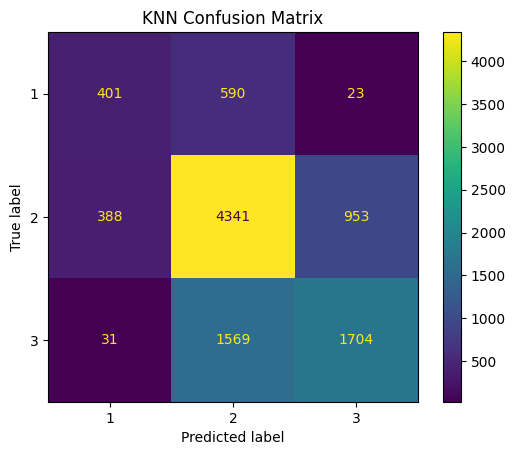

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val_knn_small,
    y_pred_knn,
    display_labels=[1, 2, 3]
)

plt.title("KNN Confusion Matrix")
plt.show()

Neural Network confusion matrix

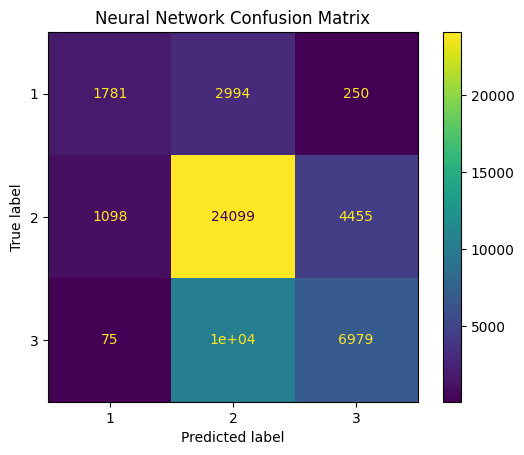

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_nn,
    display_labels=[1, 2, 3]
)

plt.title("Neural Network Confusion Matrix")
plt.show()

Random Forest confusion matrix

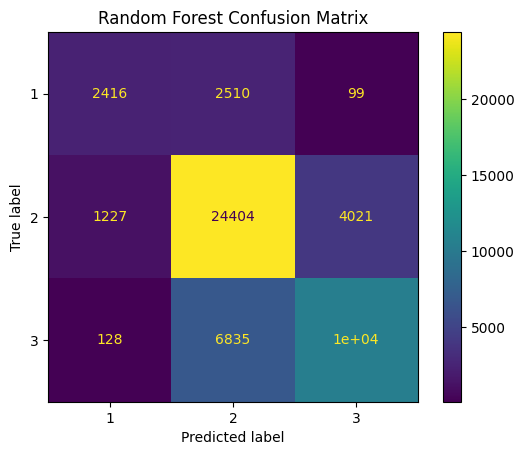

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf,
    display_labels=[1, 2, 3]
)

plt.title("Random Forest Confusion Matrix")
plt.show()

MODEL COMPARISON GRAPH

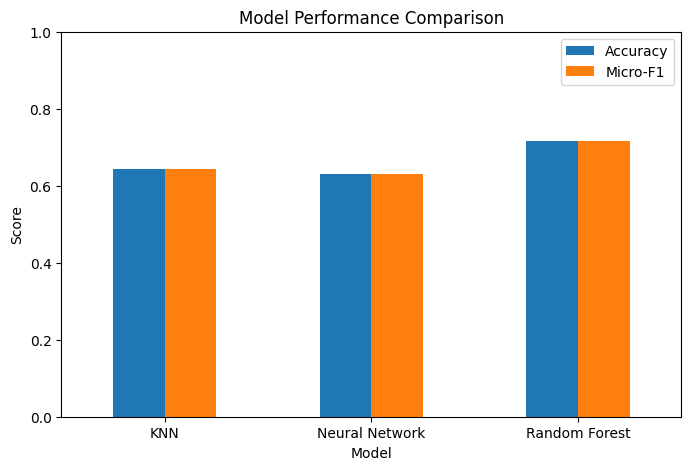

In [ ]:
results.set_index("Model")[["Accuracy", "Micro-F1"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

RANDOM FOREST FEATURE IMPORTANCE

In [ ]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
2,num__geo_level_3_id,0.152891
1,num__geo_level_2_id,0.134381
0,num__geo_level_1_id,0.133391
4,num__age,0.121340
5,num__area_percentage,0.113307
6,num__height_percentage,0.056311
18,num__count_families,0.025126
3,num__count_floors_pre_eq,0.016402
35,cat__foundation_type_r,0.014867
8,num__has_superstructure_mud_mortar_stone,0.013175


Plot top 20 features

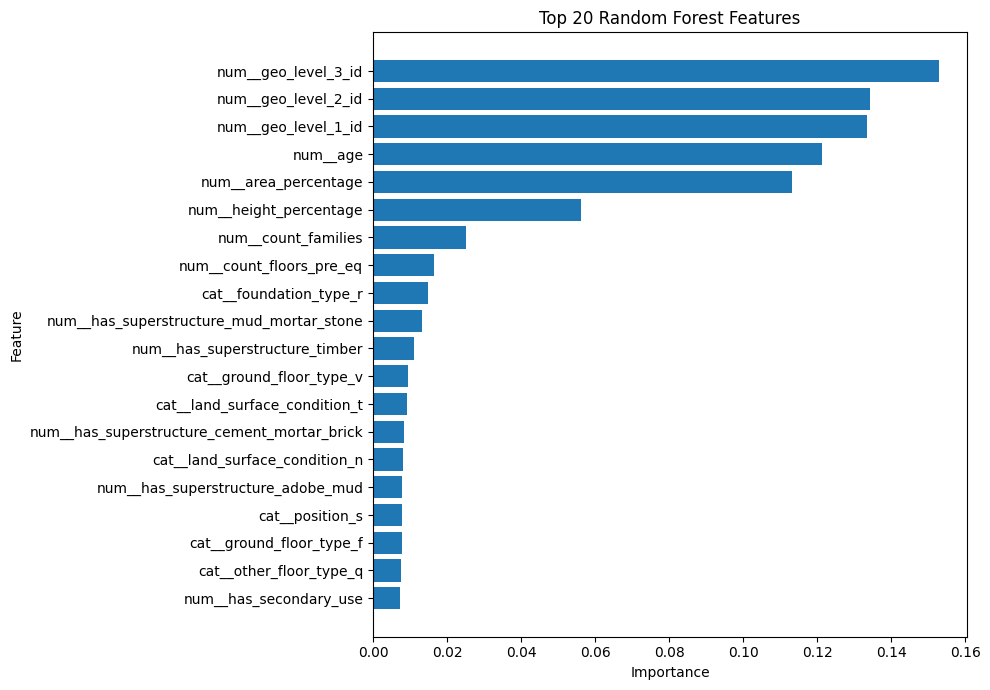

In [ ]:
top_features = feature_importance.head(20).sort_values("Importance")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Features")

plt.tight_layout()
plt.show()

USE test_values.csv

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

test_values = pd.read_csv("test_values.csv")

print("Test data shape:", test_values.shape)

Saving test_values.csv to test_values.csv
Test data shape: (86868, 39)


Separate Test Features

In [ ]:
X_test = test_values.drop(columns=["building_id"])

print("Test features shape:", X_test.shape)

Test features shape: (86868, 38)


Preprocess Test Data

In [ ]:
X_test_processed = preprocessor.transform(X_test)

print("Processed test data shape:", X_test_processed.shape)

Processed test data shape: (86868, 68)


Prepare Test Data for KNN

In [ ]:
X_test_knn = selector.transform(X_test_processed)

print("KNN test data shape:", X_test_knn.shape)

KNN test data shape: (86868, 20)


KNN Test Predictions

In [ ]:
test_pred_knn = knn.predict(X_test_knn)

print("KNN test predictions completed.")
print("First 20 predictions:")
print(test_pred_knn[:20])

KNN test predictions completed.
First 20 predictions:
[3 2 2 1 3 3 2 3 2 1 2 2 3 3 2 2 2 2 2 2]


Neural Network Test Predictions

In [ ]:
test_pred_nn = nn_model.predict(X_test_processed)

print("Neural Network test predictions completed.")
print("First 20 predictions:")
print(test_pred_nn[:20])

Neural Network test predictions completed.
First 20 predictions:
[3 2 2 1 3 3 1 2 3 2 2 2 2 3 1 3 2 2 2 2]


Random Forest Test Predictions

In [ ]:
test_pred_rf = rf_model.predict(X_test_processed)

print("Random Forest test predictions completed.")
print("First 20 predictions:")
print(test_pred_rf[:20])

Random Forest test predictions completed.
First 20 predictions:
[3 2 2 1 3 3 2 3 2 2 2 2 2 2 2 2 2 2 2 2]


Create Prediction DataFrames

In [ ]:
knn_submission = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_pred_knn
})

nn_submission = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_pred_nn
})

rf_submission = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_pred_rf
})

print("All prediction files prepared.")

All prediction files prepared.


Check Predictions

In [ ]:
print("KNN predictions:")
print(knn_submission.head())

print("\nNeural Network predictions:")
print(nn_submission.head())

print("\nRandom Forest predictions:")
print(rf_submission.head())

KNN predictions:
   building_id  damage_grade
0       300051             3
1        99355             2
2       890251             2
3       745817             1
4       421793             3

Neural Network predictions:
   building_id  damage_grade
0       300051             3
1        99355             2
2       890251             2
3       745817             1
4       421793             3

Random Forest predictions:
   building_id  damage_grade
0       300051             3
1        99355             2
2       890251             2
3       745817             1
4       421793             3


Check Damage Grade Distribution

In [ ]:
print("KNN prediction distribution:")
print(knn_submission["damage_grade"].value_counts().sort_index())

print("\nNeural Network prediction distribution:")
print(nn_submission["damage_grade"].value_counts().sort_index())

print("\nRandom Forest prediction distribution:")
print(rf_submission["damage_grade"].value_counts().sort_index())

KNN prediction distribution:
damage_grade
1     6585
2    56738
3    23545
Name: count, dtype: int64

Neural Network prediction distribution:
damage_grade
1     4867
2    62367
3    19634
Name: count, dtype: int64

Random Forest prediction distribution:
damage_grade
1     6227
2    56395
3    24246
Name: count, dtype: int64


Save KNN Prediction File

In [ ]:
knn_submission.to_csv(
    "knn_predictions.csv",
    index=False
)

print("KNN prediction file saved.")

KNN prediction file saved.


Save Neural Network Prediction File

In [ ]:
nn_submission.to_csv(
    "neural_network_predictions.csv",
    index=False
)

print("Neural Network prediction file saved.")

Neural Network prediction file saved.


Save Random Forest Prediction File

In [ ]:
rf_submission.to_csv(
    "random_forest_predictions.csv",
    index=False
)

print("Random Forest prediction file saved.")

Random Forest prediction file saved.


Download Random Forest Submission

In [ ]:
final_submission = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_pred_rf
})

final_submission.to_csv(
    "nepal_earthquake_final_predictions.csv",
    index=False
)

print("Final prediction file created.")
print(final_submission.head())

Final prediction file created.
   building_id  damage_grade
0       300051             3
1        99355             2
2       890251             2
3       745817             1
4       421793             3


Download the Final File

In [ ]:
from google.colab import files

files.download("nepal_earthquake_final_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model Comparison

In [ ]:
results = pd.DataFrame({
    "Model": [
        "KNN",
        "Neural Network",
        "Random Forest"
    ],
    "Accuracy": [
        knn_accuracy,
        nn_accuracy,
        rf_accuracy
    ],
    "Micro-F1": [
        knn_f1,
        nn_f1,
        rf_f1
    ]
})

print(results)

            Model  Accuracy  Micro-F1
0             KNN  0.644600  0.644600
1  Neural Network  0.630437  0.630437
2   Random Forest  0.715662  0.715662


Rounded Results

In [ ]:
results_rounded = results.copy()

results_rounded["Accuracy"] = results_rounded["Accuracy"].round(4)
results_rounded["Micro-F1"] = results_rounded["Micro-F1"].round(4)

results_rounded

,Model,Accuracy,Micro-F1
0,KNN,0.6446,0.6446
1,Neural Network,0.6304,0.6304
2,Random Forest,0.7157,0.7157


Comparison Graph

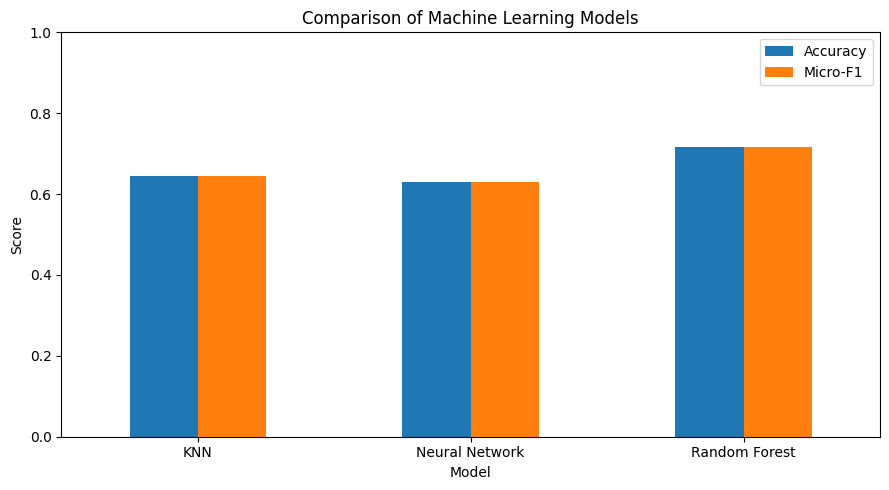

In [ ]:
import matplotlib.pyplot as plt

results_plot = results.set_index("Model")[["Accuracy", "Micro-F1"]]

results_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

KNN CONFUSION MATRIX

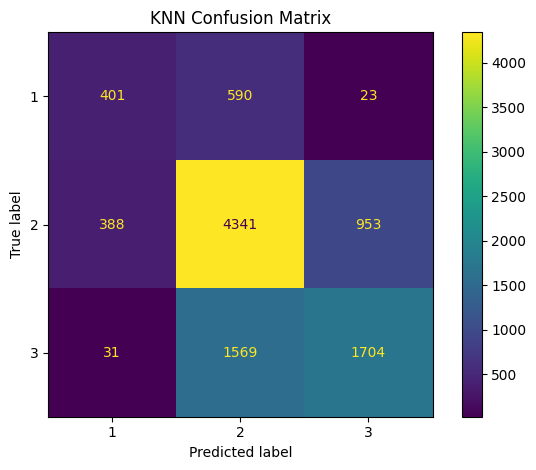

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val_knn_small,
    y_pred_knn,
    display_labels=[1, 2, 3]
)

plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

NEURAL NETWORK CONFUSION MATRIX

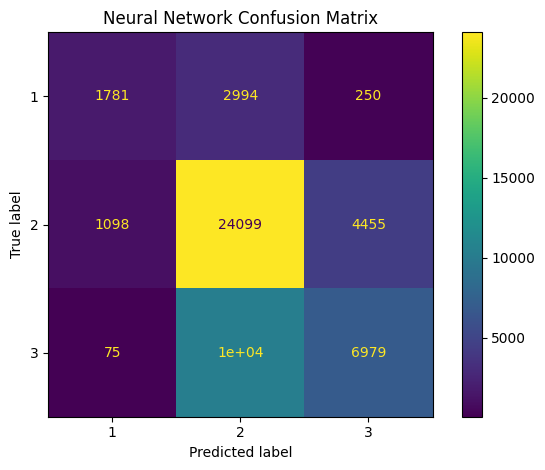

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_nn,
    display_labels=[1, 2, 3]
)

plt.title("Neural Network Confusion Matrix")
plt.tight_layout()
plt.show()

RANDOM FOREST CONFUSION MATRIX

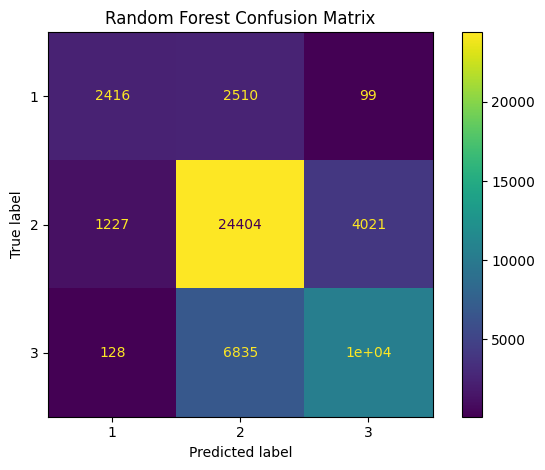

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf,
    display_labels=[1, 2, 3]
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

RANDOM FOREST FEATURE IMPORTANCE

In [ ]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Important Features:")
print(feature_importance.head(20))

Top 20 Important Features:
                                        Feature  Importance
2                           num__geo_level_3_id    0.152891
1                           num__geo_level_2_id    0.134381
0                           num__geo_level_1_id    0.133391
4                                      num__age    0.121340
5                          num__area_percentage    0.113307
6                        num__height_percentage    0.056311
18                          num__count_families    0.025126
3                      num__count_floors_pre_eq    0.016402
35                       cat__foundation_type_r    0.014867
8      num__has_superstructure_mud_mortar_stone    0.013175
13               num__has_superstructure_timber    0.011191
43                     cat__ground_floor_type_v    0.009453
32                cat__land_surface_condition_t    0.009082
12  num__has_superstructure_cement_mortar_brick    0.008289
30                cat__land_surface_condition_n    0.008116
7            

FEATURE IMPORTANCE GRAPH

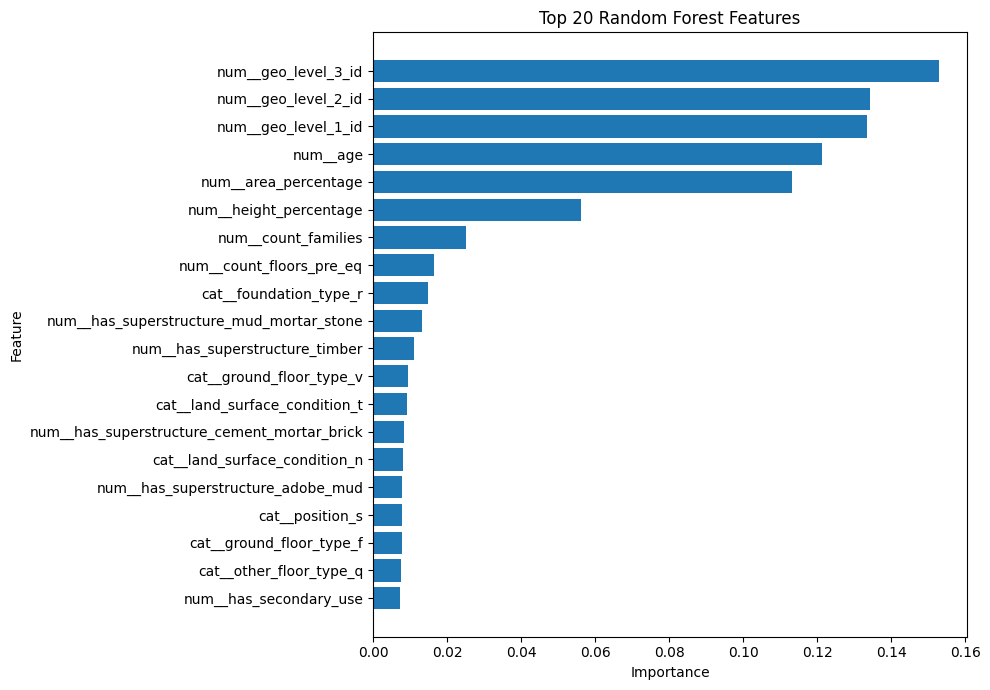

In [ ]:
top_features = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Features")

plt.tight_layout()
plt.show()

CLASS DISTRIBUTION GRAPH

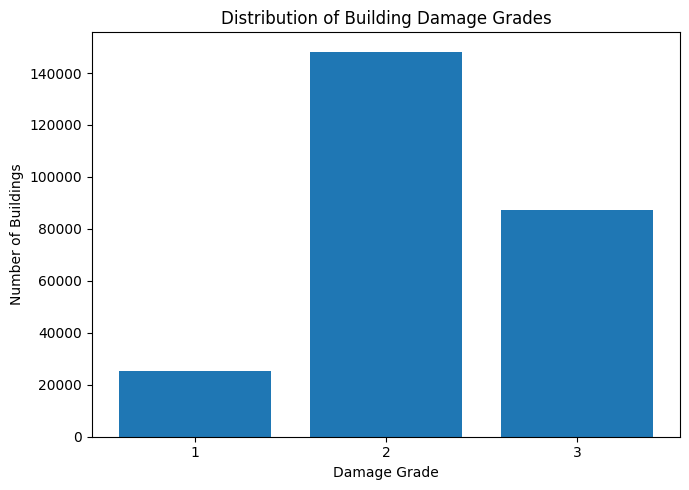

In [ ]:
damage_counts = y.value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    damage_counts.index.astype(str),
    damage_counts.values
)

plt.xlabel("Damage Grade")
plt.ylabel("Number of Buildings")
plt.title("Distribution of Building Damage Grades")

plt.tight_layout()
plt.show()

DAMAGE PERCENTAGE

In [ ]:
damage_percentage = (
    y.value_counts(normalize=True)
    .sort_index() * 100
)

print("Damage Grade Percentage Distribution:")
print(damage_percentage.round(2))

Damage Grade Percentage Distribution:
damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64


SAVE RESULTS TABLE

In [ ]:
results_rounded.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison results saved.")

Model comparison results saved.


FINAL PROJECT SUMMARY

In [ ]:
print("=" * 60)
print("NEPAL EARTHQUAKE BUILDING DAMAGE PREDICTION")
print("=" * 60)

print("\nDataset:")
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Number of features:", X.shape[1])

print("\nDamage Classes:")
print("1 = Low damage")
print("2 = Medium damage")
print("3 = Almost complete destruction")

print("\nMODEL RESULTS")
print(results_rounded.to_string(index=False))

print("\nBest performing model based on validation Micro-F1:")
best_model = results.loc[results["Micro-F1"].idxmax(), "Model"]
best_score = results["Micro-F1"].max()

print(best_model, ":", round(best_score, 4))

print("\n" + "=" * 60)

NEPAL EARTHQUAKE BUILDING DAMAGE PREDICTION

Dataset:
Training samples: 208480
Validation samples: 52121
Number of features: 38

Damage Classes:
1 = Low damage
2 = Medium damage
3 = Almost complete destruction

MODEL RESULTS
         Model  Accuracy  Micro-F1
           KNN    0.6446    0.6446
Neural Network    0.6304    0.6304
 Random Forest    0.7157    0.7157

Best performing model based on validation Micro-F1:
Random Forest : 0.7157



FAIR COMPARISON ON SAME 10,000 SAMPLES

In [ ]:
# Use the same 10,000 validation samples for all models

X_val_processed_small = X_val_processed[:10000]
y_val_small = y_val.iloc[:10000]

# Neural Network
y_pred_nn_small = nn_model.predict(X_val_processed_small)

nn_accuracy_small = accuracy_score(
    y_val_small,
    y_pred_nn_small
)

nn_f1_small = f1_score(
    y_val_small,
    y_pred_nn_small,
    average="micro"
)

# Random Forest
y_pred_rf_small = rf_model.predict(X_val_processed_small)

rf_accuracy_small = accuracy_score(
    y_val_small,
    y_pred_rf_small
)

rf_f1_small = f1_score(
    y_val_small,
    y_pred_rf_small,
    average="micro"
)

# Comparison
fair_results = pd.DataFrame({
    "Model": [
        "KNN",
        "Neural Network",
        "Random Forest"
    ],
    "Accuracy": [
        knn_accuracy,
        nn_accuracy_small,
        rf_accuracy_small
    ],
    "Micro-F1": [
        knn_f1,
        nn_f1_small,
        rf_f1_small
    ]
})

fair_results["Accuracy"] = fair_results["Accuracy"].round(4)
fair_results["Micro-F1"] = fair_results["Micro-F1"].round(4)

print(fair_results)

            Model  Accuracy  Micro-F1
0             KNN    0.6446    0.6446
1  Neural Network    0.6329    0.6329
2   Random Forest    0.7197    0.7197


In [ ]:
print(fair_results)

            Model  Accuracy  Micro-F1
0             KNN    0.6446    0.6446
1  Neural Network    0.6329    0.6329
2   Random Forest    0.7197    0.7197


colab

In [ ]:
fair_results.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("model_comparison_results.csv created successfully!")

model_comparison_results.csv created successfully!


In [ ]:
from google.colab import files

files.download("model_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>